# Planner

Goal: take a mission file (JSON) and predict the battery voltage along the mission.

Steps, one at a time:
1. Read the mission file and look at the legs
2. Solar along the mission
3. Load along the mission
4. Total power, then battery voltage (rollout, no replanning)

**Part 2: planners** (sections 8+)
- Fixed solution space: **one speed per hour**, from 0.0 to 1.4 m/s in 0.2 steps.
- Goal (no `arrive_by`): earliest arrival at the last waypoint, voltage ≥ `reserve_v` the whole way.
- Goal (with `arrive_by`): arrive by the deadline with the **highest lowest voltage** (most margin at the worst moment).
- `Problem` holds everything fixed and simulates a plan; each planner only has to return a list of hourly speeds.

## 1. The mission file

`mission.json` holds:
- `start_time` (UTC) and `start_v` (voltage at the start)
- `speed_ms`: the constant default speed
- `reserve_v`: the minimum voltage to keep
- `arrive_by` (optional, UTC): deadline at the last waypoint (used by the planners in Part 2)
- `starlink`: simple schedule, on at `at_min` past every `every_h` hours (counted from `first_h` UTC) for `on_min` minutes
- `waypoints`: list of `lat`/`lon`. The boat starts at the first one.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

with open("mission.json") as f:
    mission = json.load(f)

mission

{'start_time': '2025-07-15T06:00:00Z',
 'start_v': 24.0,
 'speed_ms': 1.0,
 'reserve_v': 23.0,
 'arrive_by': '2025-07-22T12:00:00Z',
 'starlink': {'every_h': 2, 'first_h': 0, 'at_min': 47, 'on_min': 8},
 'waypoints': [{'lat': 60.4609, 'lon': 1.7663},
  {'lat': 60.8, 'lon': 1.3},
  {'lat': 61.1885, 'lon': 0.8526},
  {'lat': 61.3227, 'lon': 0.9548},
  {'lat': 60.3609, 'lon': 1.7663},
  {'lat': 60.6, 'lon': 1.3},
  {'lat': 61.0, 'lon': 0.8526},
  {'lat': 61.0, 'lon': 0.9548}]}

## 2. Legs

A leg joins two waypoints in a row. Distance = great-circle (haversine).
Time = distance / `speed_ms`.

In [2]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

wps = pd.DataFrame(mission["waypoints"])
speed = mission["speed_ms"]

legs = pd.DataFrame({
    "from_wp": wps.index[:-1],
    "to_wp": wps.index[1:],
    "km": haversine_km(wps.lat.values[:-1], wps.lon.values[:-1],
                       wps.lat.values[1:], wps.lon.values[1:]),
})
legs["hours"] = legs.km * 1000 / speed / 3600
legs["arrive"] = (pd.Timestamp(mission["start_time"]) + pd.to_timedelta(legs.hours.cumsum(), unit="h")).dt.floor("min")
legs.round({"km": 2, "hours": 2})

,from_wp,to_wp,km,hours,arrive
0,0,1,45.48,12.63,2025-07-15 18:37:00+00:00
1,1,2,49.48,13.74,2025-07-16 08:22:00+00:00
2,2,3,15.89,4.41,2025-07-16 12:47:00+00:00
3,3,4,115.63,32.12,2025-07-17 20:54:00+00:00
4,4,5,36.87,10.24,2025-07-18 07:09:00+00:00
5,5,6,50.67,14.07,2025-07-18 21:13:00+00:00
6,6,7,5.51,1.53,2025-07-18 22:45:00+00:00


In [3]:
print(f"Total: {legs.km.sum():.1f} km, {legs.hours.sum():.1f} h at {speed} m/s")

Total: 319.5 km, 88.8 h at 1.0 m/s


## 3. Plot: the route

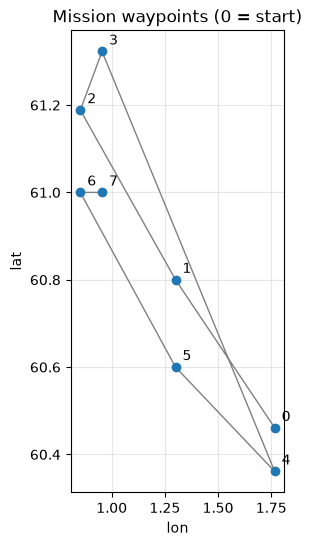

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(wps.lon, wps.lat, "-", color="grey", lw=1)
ax.scatter(wps.lon, wps.lat, color="C0", zorder=3)
for i, r in wps.iterrows():
    ax.annotate(str(i), (r.lon, r.lat), xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("lon")
ax.set_ylabel("lat")
ax.set_title("Mission waypoints (0 = start)")
ax.set_aspect(1 / np.cos(np.radians(wps.lat.mean())))
ax.grid(alpha=0.3)
plt.show()

## 4. Solar along the mission

P_solar = k · G, with k = 0.164 m² (fixed, nb 04) and G = irradiance in W/m².

- **Plan input:** Open-Meteo forecast (`data/weather/forecast.csv`). For mission day n (0 = start day) the plan uses
  the forecast issued n+1 days earlier (`_d1`, `_d2`, `_d3`; after day 3 it keeps `_d3`). No extra margin.
- **Reference only:** ERA5 (`data/weather/truth.csv`) = what really happened. The plan never reads it.
- One weather point (60.5N 1.5E) for the whole route.
- The mission must fit inside the weather files (now 14 Jul – 11 Sep 2025), otherwise the notebook stops with an error.
- Hourly values are means over the hour *before* the timestamp, so each point sits at the middle of its hour (−30 min).
  Then they are interpolated to 1-minute steps.

In [5]:
K_SOLAR = 0.164   # m², nb 04
DT_MIN = 1

def read_weather(path):
    w = pd.read_csv(path, comment="#", parse_dates=["time"]).set_index("time")
    w.index = w.index - pd.Timedelta(minutes=30)   # hour-mean -> middle of the hour
    return w

fc = read_weather("../data/weather/forecast.csv")
era5 = read_weather("../data/weather/truth.csv")

t0 = pd.Timestamp(mission["start_time"])
t_end = t0 + pd.Timedelta(hours=legs.hours.sum())
t = pd.date_range(t0, t_end, freq=f"{DT_MIN}min")

# no silent gaps: the mission must sit inside the weather data
for name, w in [("forecast", fc), ("ERA5", era5)]:
    if t0 < w.index[0] or t_end > w.index[-1]:
        raise ValueError(f"Mission {t0:%d %b %H:%M} -> {t_end:%d %b %H:%M} runs outside the {name} data "
                         f"({w.index[0]:%d %b %H:%M} -> {w.index[-1]:%d %b %H:%M}). "
                         f"Fetch more days: .venv/bin/python sim/fetch_weather.py --days N")

def to_minutes(series):
    s = series.reindex(series.index.union(t)).interpolate(method="time")
    return s.reindex(t).values

# forecast lead per minute: day n -> lead n+1 (max 3)
day_n = (t.normalize() - t0.normalize()).days
lead = np.minimum(day_n + 1, 3)
G_fc = np.choose(lead - 1, [to_minutes(fc[f"shortwave_radiation_d{d}"]) for d in (1, 2, 3)])
G_era5 = to_minutes(era5["shortwave_radiation"])

sim = pd.DataFrame({"lead": lead, "P_solar_plan": K_SOLAR * G_fc, "P_solar_era5": K_SOLAR * G_era5}, index=t)
e_plan = sim.P_solar_plan.sum() * DT_MIN / 60 / 1000
e_era5 = sim.P_solar_era5.sum() * DT_MIN / 60 / 1000
print(f"Solar energy over the mission: plan {e_plan:.2f} kWh, ERA5 {e_era5:.2f} kWh")

Solar energy over the mission: plan 4.16 kWh, ERA5 4.12 kWh


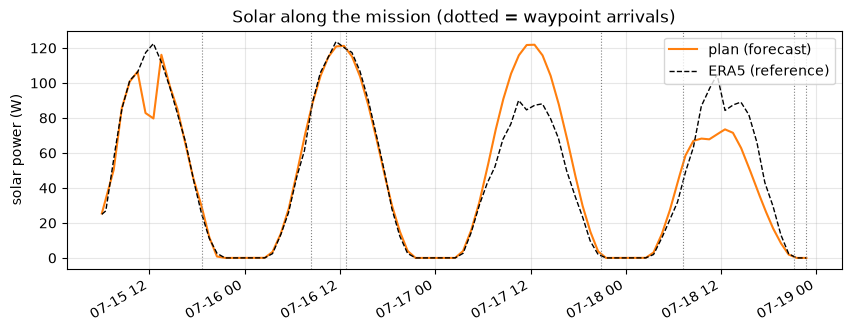

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(sim.index, sim.P_solar_plan, color="C1", label="plan (forecast)")
ax.plot(sim.index, sim.P_solar_era5, color="k", ls="--", lw=1, label="ERA5 (reference)")
for a in legs.arrive:
    ax.axvline(a, color="grey", lw=0.8, ls=":")
ax.set_ylabel("solar power (W)")
ax.set_title("Solar along the mission (dotted = waypoint arrivals)")
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

## 5. Load along the mission

load = 10 W hotel + 22 W · Starlink on + motor (nb 03).

- **Motor:** one of the three speed models from nb 03 (fitted with no intercept, MANUAL excluded). Default k·v,
  the best fit there and the one the simulator uses. The whole mission is legs at `speed_ms`, so the motor is always on.
- **Starlink:** the schedule from `mission.json`. Default copies 15–19 Jul (nb 01b): every 2 h at even hours, at :47, for 8 min.

In [7]:
HOTEL_W = 10.0
STARLINK_W = 22.0
LOAD_MODELS = {"k·v": (1, 64.81), "k·v²": (2, 54.41), "k·v³": (3, 39.32)}   # nb 03: (power of v, k)
LOAD_MODEL = "k·v"

for name, (n, k) in LOAD_MODELS.items():
    print(f"{name:5s}: motor at {speed} m/s = {k * speed ** n:.1f} W")

def starlink_on(t, sched):
    minutes_since = ((t.hour - sched["first_h"]) % sched["every_h"]) * 60 + t.minute - sched["at_min"]
    return (minutes_since >= 0) & (minutes_since < sched["on_min"])

n, k = LOAD_MODELS[LOAD_MODEL]
sim["v"] = speed                      # constant speed, whole mission is under way
sim["starlink"] = starlink_on(sim.index, mission["starlink"])
sim["P_hotel"] = HOTEL_W
sim["P_starlink"] = STARLINK_W * sim.starlink
sim["P_motor"] = k * sim.v ** n
sim["P_load"] = sim.P_hotel + sim.P_starlink + sim.P_motor

e = sim[["P_hotel", "P_starlink", "P_motor", "P_load"]].sum() * DT_MIN / 60 / 1000
print()
print(f"Load energy over the mission ({LOAD_MODEL}): " + ", ".join(f"{c[2:]} {v:.2f}" for c, v in e.items()) + " kWh")
print(f"Starlink on {sim.starlink.sum()} min in {len(sim)} min ({sim.starlink.mean():.1%})")

k·v  : motor at 1.0 m/s = 64.8 W
k·v² : motor at 1.0 m/s = 54.4 W
k·v³ : motor at 1.0 m/s = 39.3 W

Load energy over the mission (k·v): hotel 0.89, starlink 0.13, motor 5.75, load 6.77 kWh
Starlink on 352 min in 5326 min (6.6%)


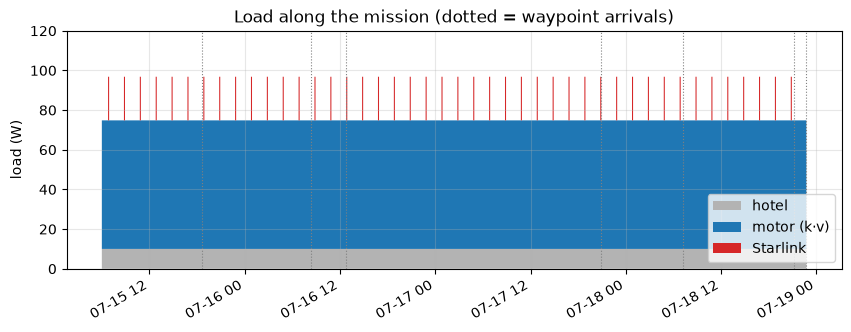

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.stackplot(sim.index, sim.P_hotel, sim.P_motor, sim.P_starlink,
             labels=["hotel", f"motor ({LOAD_MODEL})", "Starlink"], colors=["0.7", "C0", "C3"], step="post")
for a in legs.arrive:
    ax.axvline(a, color="grey", lw=0.8, ls=":")
ax.set_ylabel("load (W)")
ax.set_ylim(0, 120)
ax.set_title("Load along the mission (dotted = waypoint arrivals)")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

## 6. Total power

Battery model B1 (nb 05/06, same as `sim/env_sim.py`). Power into the battery:

P_net = η · P_solar − P_load − P_drain, with η = 1.138 and P_drain = −0.312 W (both fitted in nb 05; η > 1 is not physical, see the nb 05 notes).

In [9]:
BATT_ETA = 1.138
BATT_P_DRAIN_W = -0.312

sim["P_net"] = BATT_ETA * sim.P_solar_plan - sim.P_load - BATT_P_DRAIN_W

e_net = sim.P_net.sum() * DT_MIN / 60 / 1000
print(f"Net energy over the mission: {e_net:+.2f} kWh "
      f"(solar into battery {BATT_ETA * e_plan:.2f}, load {sim.P_load.sum() * DT_MIN / 60 / 1000:.2f})")
print(f"Positive (charging) {(sim.P_net > 0).mean():.0%} of the time, peak {sim.P_net.max():+.0f} W, lowest {sim.P_net.min():+.0f} W")

Net energy over the mission: -2.01 kWh (solar into battery 4.73, load 6.77)
Positive (charging) 37% of the time, peak +64 W, lowest -96 W


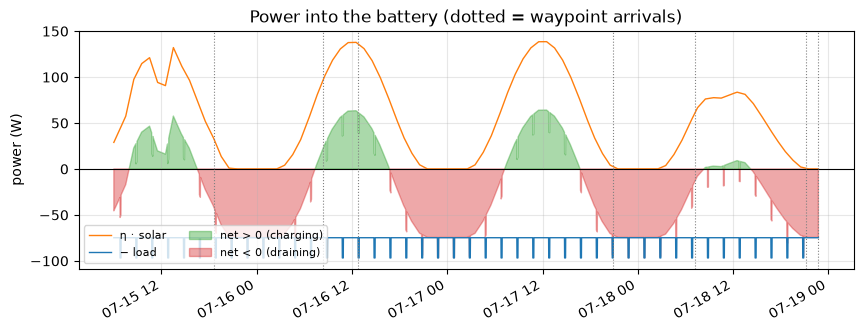

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(sim.index, BATT_ETA * sim.P_solar_plan, color="C1", lw=1, label="η · solar")
ax.plot(sim.index, -sim.P_load, color="C0", lw=1, label="− load")
ax.fill_between(sim.index, 0, sim.P_net, where=sim.P_net > 0, color="C2", alpha=0.4, label="net > 0 (charging)")
ax.fill_between(sim.index, 0, sim.P_net, where=sim.P_net <= 0, color="C3", alpha=0.4, label="net < 0 (draining)")
ax.axhline(0, color="k", lw=0.8)
for a in legs.arrive:
    ax.axvline(a, color="grey", lw=0.8, ls=":")
ax.set_ylabel("power (W)")
ax.set_title("Power into the battery (dotted = waypoint arrivals)")
ax.legend(loc="lower left", fontsize=8, ncol=2)
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

## 7. Battery voltage (rollout)

Same steps as `Battery.step()` in `sim/env_sim.py`:
- OCV += P_net · dt / k, k = 420.3 Wh per volt
- terminal V = OCV + R · I, with I = P_net / V and R = 39.2 mΩ
- no charging above 25.0 V (extra solar is lost); nothing more drawn below 20.0 V (flat)
- start: `start_v` from the JSON is taken as the OCV

No replanning: the boat follows the legs whatever happens. The reserve is only drawn as a line here.

In [11]:
BATT_K_WH_PER_V = 420.3
R_INTERNAL_OHM = 0.03921
V_CAP = 25.0
V_EMPTY = 20.0

def rollout(p_net_w, v_start, dt_s):
    ocv, v = v_start, v_start
    out_v, out_ocv = [], []
    for p_net in p_net_w:
        i_b = p_net / v
        v = ocv + R_INTERNAL_OHM * i_b
        if p_net > 0 and v > V_CAP:                       # full: limit the charge current
            i_b = max((V_CAP - ocv) / R_INTERNAL_OHM, 0.0)
            v = max(ocv + R_INTERNAL_OHM * i_b, ocv)
            p_net = i_b * v
        if p_net < 0 and ocv <= V_EMPTY:                  # flat
            p_net, v = 0.0, ocv
        ocv += p_net * dt_s / 3600 / BATT_K_WH_PER_V
        out_v.append(v)
        out_ocv.append(ocv)
    return np.array(out_v), np.array(out_ocv)

sim["V"], sim["OCV"] = rollout(sim.P_net.values, mission["start_v"], DT_MIN * 60)

reserve = mission["reserve_v"]
i_min = sim.V.idxmin()
print(f"Start {mission['start_v']:.2f} V -> end {sim.V.iloc[-1]:.2f} V (OCV {sim.OCV.iloc[-1]:.2f} V)")
print(f"Lowest {sim.V.min():.2f} V at {i_min:%d %b %H:%M}, reserve {reserve:.2f} V")
print(f"Minutes under the reserve: {(sim.V < reserve).sum()}")

Start 24.00 V -> end 20.00 V (OCV 20.00 V)
Lowest 19.91 V at 18 Jul 17:56, reserve 23.00 V
Minutes under the reserve: 3711


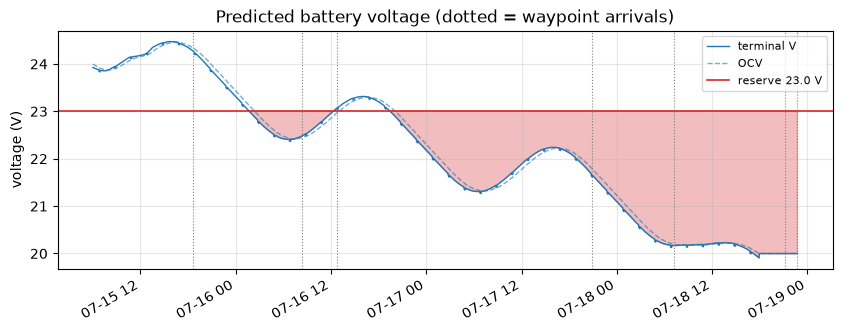

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(sim.index, sim.V, color="C0", lw=1, label="terminal V")
ax.plot(sim.index, sim.OCV, color="C0", lw=1, ls="--", alpha=0.6, label="OCV")
ax.axhline(reserve, color="C3", lw=1.2, label=f"reserve {reserve} V")
ax.fill_between(sim.index, sim.V, reserve, where=sim.V < reserve, color="C3", alpha=0.3)
for a in legs.arrive:
    ax.axvline(a, color="grey", lw=0.8, ls=":")
ax.set_ylabel("voltage (V)")
ax.set_title("Predicted battery voltage (dotted = waypoint arrivals)")
ax.legend(loc="upper right", fontsize=8)
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

# Part 2: planners

## 8. The problem

`Problem` holds everything that does not change between planners: route, start, plan solar (forecast), Starlink,
load model and battery model. It runs a plan **minute by minute** with the same steps as sections 5–7.

- **A plan** = list of hourly speeds, each from `SPEEDS` (0.0, 0.2, … 1.4 m/s; 1.5 is not on the 0.2 grid).
  v = 0 means motor off (hotel + Starlink only).
- **Distance** is added up minute by minute; the mission ends when it reaches the route length.
- **Deadline:** if `arrive_by` is set, plans are `n_hours` long (start → deadline, rounded down to whole hours).
- **Feasible** = arrives before the plan (or the weather data, or the deadline) runs out, and V ≥ `reserve_v` until arrival.
- `run()` can start from any hour and battery state, so planners can try "what if" pieces of a plan.
- `evaluate()` runs a whole plan from the start and returns the minute table + a summary.

In [13]:
SPEEDS = np.round(np.arange(0, 1.5 + 1e-9, 0.2), 1)   # 0.0 … 1.4 m/s
print("SPEEDS:", SPEEDS)

class Problem:
    def __init__(self, mission, load_model=LOAD_MODEL):
        self.mission = mission
        self.t0 = pd.Timestamp(mission["start_time"])
        self.start_v = mission["start_v"]
        self.reserve = mission["reserve_v"]
        w = pd.DataFrame(mission["waypoints"])
        self.leg_end_km = np.cumsum(haversine_km(w.lat.values[:-1], w.lon.values[:-1], w.lat.values[1:], w.lon.values[1:]))
        self.route_km = self.leg_end_km[-1]

        # minute grid: from the start to the end of the weather data
        end = min(fc.index[-1], era5.index[-1])
        self.horizon_h = int((end - self.t0) / pd.Timedelta(hours=1))
        self.t = pd.date_range(self.t0, periods=self.horizon_h * 60, freq="min")

        # optional deadline: plans are n_hours long
        self.deadline = pd.Timestamp(mission["arrive_by"]) if mission.get("arrive_by") else None
        if self.deadline is not None:
            self.n_hours = int((self.deadline - self.t0) / pd.Timedelta(hours=1))
            if self.n_hours > self.horizon_h:
                raise ValueError(f"arrive_by {self.deadline} is after the end of the weather data ({end})")
        else:
            self.n_hours = self.horizon_h

        # plan solar: forecast, day n uses lead n+1 (max 3), as in section 4
        lead = np.minimum((self.t.normalize() - self.t0.normalize()).days + 1, 3)
        def at_minutes(series):
            return series.reindex(series.index.union(self.t)).interpolate(method="time").reindex(self.t).values
        G = np.choose(lead - 1, [at_minutes(fc[f"shortwave_radiation_d{d}"]) for d in (1, 2, 3)])
        self.p_solar = K_SOLAR * G
        self.starlink = starlink_on(self.t, mission["starlink"])
        self.p_fixed = HOTEL_W + STARLINK_W * self.starlink   # load without the motor
        self.load_model = load_model
        self.n, self.k = LOAD_MODELS[load_model]

    def start_state(self):
        return {"ocv": self.start_v, "v_term": self.start_v, "km": 0.0}

    def motor_w(self, v):
        return self.k * v ** self.n if v > 0 else 0.0

    def run(self, speeds, state, h0=0, check_reserve=False, record=False):
        """Simulate hours h0, h0+1, ... at the given hourly speeds.
        Returns (state after, minute records or None, status).
        status: 'arrived' | 'below_reserve' (only if check_reserve) | 'out_of_data' | 'ok' (plan ran out first)"""
        ocv, v_term, km = state["ocv"], state["v_term"], state["km"]
        rec = [] if record else None
        for i, v in enumerate(speeds):
            p_motor = self.motor_w(v)
            for m in range(60):
                idx = (h0 + i) * 60 + m
                if idx >= len(self.t):
                    return {"ocv": ocv, "v_term": v_term, "km": km}, rec, "out_of_data"
                p_load = self.p_fixed[idx] + p_motor
                p_net = BATT_ETA * self.p_solar[idx] - p_load - BATT_P_DRAIN_W
                # battery step: same as rollout() in section 7
                i_b = p_net / v_term
                v_term = ocv + R_INTERNAL_OHM * i_b
                if p_net > 0 and v_term > V_CAP:
                    i_b = max((V_CAP - ocv) / R_INTERNAL_OHM, 0.0)
                    v_term = max(ocv + R_INTERNAL_OHM * i_b, ocv)
                    p_net = i_b * v_term
                if p_net < 0 and ocv <= V_EMPTY:
                    p_net, v_term = 0.0, ocv
                ocv += p_net / 60 / BATT_K_WH_PER_V
                km += v * 60 / 1000
                if record:
                    rec.append((self.t[idx], v, self.p_solar[idx], p_load, p_net, v_term, ocv, km))
                st = {"ocv": ocv, "v_term": v_term, "km": km}
                if km >= self.route_km:
                    return st, rec, "arrived"
                if check_reserve and v_term < self.reserve:
                    return st, rec, "below_reserve"
        return {"ocv": ocv, "v_term": v_term, "km": km}, rec, "ok"

    def evaluate(self, plan):
        _, rec, status = self.run(plan, self.start_state(), record=True)
        df = pd.DataFrame(rec, columns=["t", "v", "P_solar", "P_load", "P_net", "V", "OCV", "km"]).set_index("t")
        arrived = status == "arrived"
        summary = {
            "status": status,
            "arrival": df.index[-1] if arrived else pd.NaT,
            "hours": len(df) / 60 if arrived else np.nan,
            "min_V": df.V.min(),
            "min_under_reserve": int((df.V < self.reserve).sum()),
            "on_time": arrived and (self.deadline is None or df.index[-1] <= self.deadline),
        }
        summary["feasible"] = summary["on_time"] and df.V.min() >= self.reserve
        return df, summary

problem = Problem(mission)
print(f"Route {problem.route_km:.1f} km, start {problem.t0:%d %b %H:%M}, reserve {problem.reserve} V, "
      f"horizon {problem.horizon_h} h (end of weather data), load model {problem.load_model}")
if problem.deadline is not None:
    print(f"Deadline {problem.deadline:%d %b %H:%M} -> plans are {problem.n_hours} h long, "
          f"average speed needed {problem.route_km * 1000 / problem.n_hours / 3600:.2f} m/s")

SPEEDS: [0.  0.2 0.4 0.6 0.8 1.  1.2 1.4]
Route 319.5 km, start 15 Jul 06:00, reserve 23.0 V, horizon 1408 h (end of weather data), load model k·v
Deadline 22 Jul 12:00 -> plans are 174 h long, average speed needed 0.51 m/s


## 9. Planners

Every planner is a class with `solve(problem)` → list of hourly speeds. Nothing else.
To add a heuristic: write a new class, then put it in the list in section 10.

- **ConstantSpeed** = your manual method: the fastest single speed from `SPEEDS` that arrives with V ≥ reserve.
  With a deadline: the slowest grid speed that still arrives on time (route ÷ hours, rounded up to the grid).
- **SlowDown(nominal, v_min)**: follow the mission speed, slow down only where the battery needs it.
  1. every hour at `nominal` (the mission speed, default 1.0 m/s)
  2. simulate; find the first minute under the reserve
  3. take the **latest hour before it** that is still above `v_min` and lower it by one step (−0.2)
  4. repeat until feasible, or nothing is left to slow down (= infeasible with these limits)

  Never faster than `nominal`, never slower than `v_min` (default 0.4 m/s ≈ measured drift, so the boat never just drifts).
  Latest hour first, because energy saved right before the problem is not lost to the 25 V cap.
- **Greedy(lookahead_h)**: the old heuristic (fastest speed that survives `lookahead_h` h of drift). Kept for comparison.
- **ShiftEnergy(v_min, v_max)** (needs `arrive_by`): goal = **highest lowest voltage**, arriving on time.
  1. start from the constant on-time plan
  2. simulate; find the hour of the lowest voltage (`h_worst`)
  3. **take** 0.2 m/s from an hour at or before `h_worst` (latest first, if above `v_min`)
  4. if the plan no longer arrives on time, **give** 0.2 m/s to the hour with the highest voltage
     (below `v_max`, and either after `h_worst` or at the 25 V cap, where the energy is free)
  5. keep the move only if the lowest voltage goes up; stop when no move helps

  SlowDown and Greedy still aim for the earliest arrival; with a deadline they are only checked against it.

In [14]:
import math, time

class Planner:
    name = "planner"
    def solve(self, problem):
        raise NotImplementedError

class ConstantSpeed(Planner):
    name = "constant"
    def solve(self, problem):
        if problem.deadline is not None:
            need = problem.route_km * 1000 / (problem.n_hours * 3600)          # m/s to arrive on time
            ok = [v for v in SPEEDS if v >= need - 1e-9]
            return [ok[0] if ok else SPEEDS[-1]] * problem.n_hours
        for v in SPEEDS[::-1]:
            if v == 0:
                break
            hours = math.ceil(problem.route_km * 1000 / v / 3600)
            _, _, status = problem.run([v] * hours, problem.start_state(), check_reserve=True)
            if status == "arrived":
                return [v] * hours
        return []   # no constant speed works

class Greedy(Planner):
    def __init__(self, lookahead_h=24):
        self.lookahead_h = lookahead_h
        self.name = f"greedy ({lookahead_h} h drift check)"
    def solve(self, problem):
        state, plan = problem.start_state(), []
        for h in range(problem.horizon_h):
            for v in SPEEDS[::-1]:                                    # fastest first
                trial = [v] + [0.0] * self.lookahead_h                # this hour at v, then drift
                _, _, status = problem.run(trial, state, h0=h, check_reserve=True)
                if status != "below_reserve":
                    break
            plan.append(v)
            state, _, status = problem.run([v], state, h0=h)
            if status in ("arrived", "out_of_data"):
                break
        return plan

class SlowDown(Planner):
    def __init__(self, nominal=1.0, v_min=0.4, step=0.2):
        self.nominal, self.v_min, self.step = nominal, v_min, step
        self.name = f"slow-down ({nominal}, min {v_min})"
    def solve(self, problem):
        plan = [self.nominal] * problem.horizon_h
        self.iterations = 0
        while True:
            self.iterations += 1
            _, rec, status = problem.run(plan, problem.start_state(), check_reserve=True, record=True)
            if status != "below_reserve":
                break                                          # feasible, or out of data / plan
            h_bad = (len(rec) - 1) // 60                       # hour of the first minute under the reserve
            slower = [h for h in range(h_bad, -1, -1) if plan[h] > self.v_min + 1e-9]
            if not slower:
                break                                          # nothing left to slow: infeasible
            h = slower[0]
            plan[h] = round(max(plan[h] - self.step, self.v_min), 1)
        n_used = math.ceil(len(rec) / 60)
        return plan[:n_used]

class ShiftEnergy(Planner):
    def __init__(self, v_min=0.4, v_max=1.0, step=0.2, max_iter=3000):
        self.v_min, self.v_max, self.step, self.max_iter = v_min, v_max, step, max_iter
        self.name = f"shift-energy ({v_min}–{v_max})"

    def _score(self, problem, plan):
        """(on time?, lowest V, minute records)"""
        _, rec, status = problem.run(plan, problem.start_state(), record=True)
        return status == "arrived", min(r[5] for r in rec), rec

    def solve(self, problem):
        if problem.deadline is None:
            raise ValueError("ShiftEnergy needs arrive_by in the mission")
        plan = ConstantSpeed().solve(problem)
        plan = [min(max(v, self.v_min), self.v_max) for v in plan]
        on_time, best, rec = self._score(problem, plan)
        self.iterations = 0
        while self.iterations < self.max_iter:
            self.iterations += 1
            V = np.array([r[5] for r in rec])
            n = len(rec)
            h_worst = int(np.argmin(V)) // 60
            V_hour = [V[h * 60:(h + 1) * 60] for h in range(math.ceil(n / 60))]
            # give candidate: highest mean V, after h_worst or at the cap
            give = [h for h in range(len(plan))
                    if plan[h] < self.v_max - 1e-9
                    and (h > h_worst or (h < len(V_hour) and V_hour[h].max() >= V_CAP - 0.01))]
            mean_V = lambda h: V_hour[h].mean() if h < len(V_hour) else V[-1]
            give.sort(key=mean_V, reverse=True)

            improved = False
            for h_take in [h for h in range(min(h_worst, len(plan) - 1), -1, -1) if plan[h] > self.v_min + 1e-9]:
                trial = plan.copy()
                trial[h_take] = round(trial[h_take] - self.step, 1)
                ok, low, trial_rec = self._score(problem, trial)
                if not ok:                                          # late now: give the speed back elsewhere
                    g = next((h for h in give if h != h_take), None)
                    if g is None:
                        continue
                    trial[g] = round(trial[g] + self.step, 1)
                    ok, low, trial_rec = self._score(problem, trial)
                if ok and low > best + 1e-4:
                    plan, best, rec, improved = trial, low, trial_rec, True
                    break
            if not improved:
                break
        return plan

## 10. Compare the planners

`compare(problem, planners)` runs each planner, evaluates its plan with the same `Problem`, and shows a table + plot.
Call it with any list, e.g. `compare(problem, [SlowDown(v_min=0.2), SlowDown(v_min=0.6)])`.

In [15]:
def compare(problem, planners, plot=True):
    results = {}
    for p in planners:
        tic = time.time()
        plan = p.solve(problem)
        df, summary = problem.evaluate(plan)
        summary["solve_s"] = round(time.time() - tic, 1)
        summary["mean_v"] = round(df.v.mean(), 2)
        summary["min_v"] = df.v.min()
        summary["max_v"] = df.v.max()
        summary["iterations"] = getattr(p, "iterations", None)
        results[p.name] = (plan, df, summary)

    if plot:
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
        for i, (name, (plan, df, s)) in enumerate(results.items()):
            hourly_t = problem.t0 + pd.to_timedelta(np.arange(len(plan)), unit="h")
            ax1.step(hourly_t, plan, where="post", color=f"C{i}", label=name)
            ax2.plot(df.index, df.V, color=f"C{i}", lw=1, label=name)
            if s["feasible"]:
                ax2.axvline(s["arrival"], color=f"C{i}", ls=":", lw=1)
        ax2.axhline(problem.reserve, color="C3", lw=1.2, label=f"reserve {problem.reserve} V")
        if problem.deadline is not None:
            for ax in (ax1, ax2):
                ax.axvline(problem.deadline, color="k", lw=1.5, ls="--")
            ax2.text(problem.deadline, ax2.get_ylim()[1], " deadline", va="top", fontsize=8)
        ax1.set_ylabel("speed (m/s)")
        ax1.set_ylim(-0.05, 1.5)
        ax1.set_title("Hourly speed plan per planner")
        ax1.legend(fontsize=8)
        ax2.set_ylabel("voltage (V)")
        ax2.set_title("Predicted voltage (dotted = arrival, dashed = deadline)")
        ax2.legend(fontsize=8)
        for ax in (ax1, ax2):
            ax.grid(alpha=0.3)
        fig.autofmt_xdate()
        plt.show()

    table = pd.DataFrame({name: r[2] for name, r in results.items()}).T
    return table, results

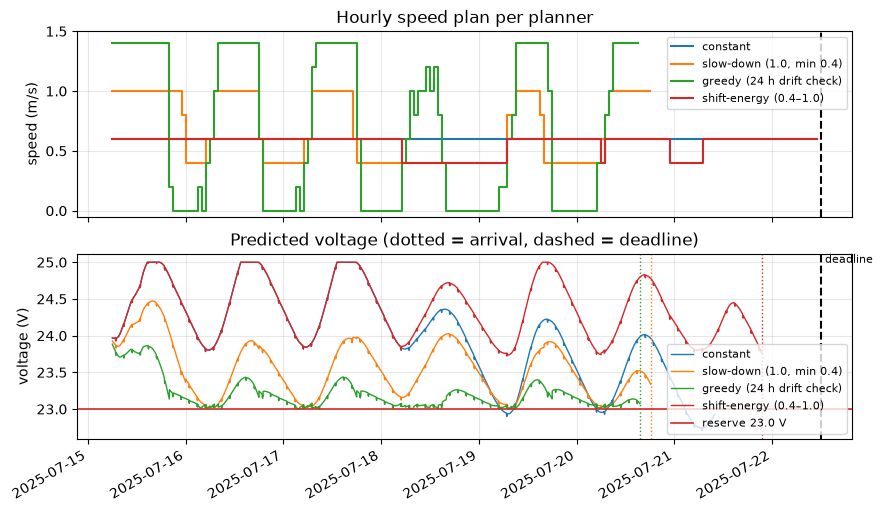

,status,arrival,hours,min_V,min_under_reserve,on_time,feasible,solve_s,mean_v,min_v,max_v,iterations
constant,arrived,2025-07-21 09:55:00+00:00,147.933333,22.703822,784,True,False,0.1,0.6,0.6,0.6,None
"slow-down (1.0, min 0.4)",arrived,2025-07-20 18:09:00+00:00,132.166667,23.003964,0,True,True,12.1,0.67,0.4,1.0,218
greedy (24 h drift check),arrived,2025-07-20 15:32:00+00:00,129.55,23.000033,0,True,True,0.8,0.69,0.0,1.4,None
shift-energy (0.4–1.0),arrived,2025-07-21 21:35:00+00:00,159.6,23.722332,0,True,True,12.3,0.56,0.4,0.6,36


In [16]:
table, results = compare(problem, [ConstantSpeed(), SlowDown(nominal=1.0, v_min=0.4), Greedy(lookahead_h=24),
                                  ShiftEnergy(v_min=0.4, v_max=1.0)], plot=True)
table

## 11. Predicted vs actual voltage

Uses the **shift-energy** plan from section 10. Same hourly speeds, same Starlink, same load and battery model.
The only change is the solar input:
- **predicted** = plan solar (Open-Meteo forecast), as the planner saw it
- **actual** = ERA5 solar × 0.164 (what really happened, the reference from section 4)

So the gap between the two lines is just the forecast error in the weather, carried through the battery.

Plan: shift-energy (0.4–1.0), 174 h
Solar over the run: predicted 6.89 kWh, actual 7.11 kWh
Lowest V: predicted 23.72, actual 23.37 (reserve 23.0)
End V: predicted 23.75, actual 24.41
Error (pred − act): mean -0.01 V, RMSE 0.27 V, largest 0.67 V; actual under reserve 0 min


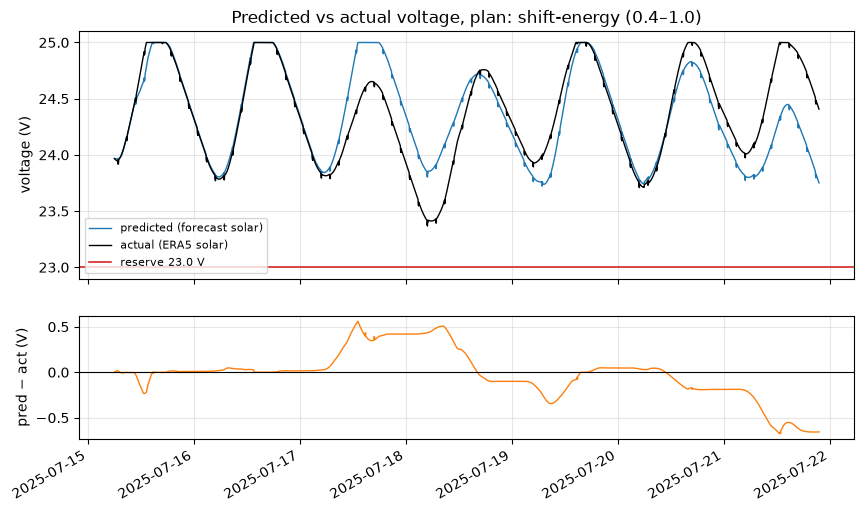

In [17]:
import copy

PLAN_NAME = [n for n in results if n.startswith("shift-energy")][0]
plan, df_pred, s_pred = results[PLAN_NAME]

# same problem, ERA5 solar instead of the forecast
actual = copy.copy(problem)
actual.p_solar = K_SOLAR * era5["shortwave_radiation"].reindex(era5.index.union(problem.t)) \
                               .interpolate(method="time").reindex(problem.t).values
df_act, s_act = actual.evaluate(plan)

both = pd.DataFrame({"pred": df_pred.V, "act": df_act.V}).dropna()
err = both.pred - both.act
print(f"Plan: {PLAN_NAME}, {len(plan)} h")
print(f"Solar over the run: predicted {df_pred.P_solar.sum() / 60 / 1000:.2f} kWh, actual {df_act.P_solar.sum() / 60 / 1000:.2f} kWh")
print(f"Lowest V: predicted {s_pred['min_V']:.2f}, actual {s_act['min_V']:.2f} (reserve {problem.reserve})")
print(f"End V: predicted {df_pred.V.iloc[-1]:.2f}, actual {df_act.V.iloc[-1]:.2f}")
print(f"Error (pred − act): mean {err.mean():+.2f} V, RMSE {np.sqrt((err ** 2).mean()):.2f} V, "
      f"largest {err.abs().max():.2f} V; actual under reserve {s_act['min_under_reserve']} min")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(df_pred.index, df_pred.V, color="C0", lw=1, label="predicted (forecast solar)")
ax1.plot(df_act.index, df_act.V, color="k", lw=1, label="actual (ERA5 solar)")
ax1.axhline(problem.reserve, color="C3", lw=1.2, label=f"reserve {problem.reserve} V")
ax1.set_ylabel("voltage (V)")
ax1.set_title(f"Predicted vs actual voltage, plan: {PLAN_NAME}")
ax1.legend(fontsize=8)
ax2.plot(both.index, err, color="C1", lw=1)
ax2.axhline(0, color="k", lw=0.8)
ax2.set_ylabel("pred − act (V)")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()